<a href="https://colab.research.google.com/github/thomasdukullay/Duks-/blob/main/Supply.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [5]:
import pandas as pd
df = pd.read_csv('/content/synthetic_ecommerce_order_risk_dataset1.csv')
df

,order_id,order_date,country,device_type,traffic_source,payment_method,product_category,customer_age_days,previous_orders,avg_order_value_eur,...,shipping_distance_km,delivery_days_estimated,late_delivery_risk,address_mismatch,high_risk_ip,customer_support_contacts,review_score,is_returned,is_fraud,risk_label
0,ORD-2024-001936,1/3/2024,Belgium,Mobile,Paid Ads,Credit Card,Sports,381,3,28.66,...,105.7,5,0,0,0,0,4.4,0,0,Normal
1,ORD-2025-006495,11/26/2025,Netherlands,Desktop,Email,Debit Card,Garden,561,6,41.93,...,528.2,4,0,0,0,0,4.8,0,0,Normal
2,ORD-2023-001721,11/7/2023,Netherlands,Mobile,Organic Search,Debit Card,Garden,324,2,102.67,...,175.1,5,0,0,0,0,3.3,0,0,Normal
3,ORD-2024-009121,5/28/2024,Netherlands,Mobile,Organic Search,Klarna,Electronics,378,3,72.71,...,271.4,3,0,0,0,0,4.2,1,0,Return Risk
4,ORD-2025-000361,1/31/2025,Netherlands,Desktop,Direct,Bank Transfer,Home & Kitchen,447,5,52.26,...,285.3,3,0,1,0,0,5.0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,ORD-2023-011965,2/19/2023,France,Mobile,Social Media,Credit Card,Garden,742,3,25.75,...,121.4,3,0,0,0,1,4.5,0,0,Normal
11996,ORD-2023-005192,5/12/2023,France,Mobile,Organic Search,Debit Card,Fashion,152,1,96.29,...,225.5,4,0,0,0,0,5.0,0,0,Normal
11997,ORD-2024-005391,6/13/2024,Germany,Mobile,Organic Search,Credit Card,Fashion,130,0,114.14,...,669.6,5,0,0,0,0,4.5,0,0,Normal
11998,ORD-2025-000861,4/4/2025,Poland,Desktop,Marketplace,PayPal,Fashion,203,1,21.60,...,229.4,5,0,0,0,0,4.4,0,0,Normal


In [10]:
df.drop_duplicates()

,order_id,order_date,country,device_type,traffic_source,payment_method,product_category,customer_age_days,previous_orders,avg_order_value_eur,...,shipping_distance_km,delivery_days_estimated,late_delivery_risk,address_mismatch,high_risk_ip,customer_support_contacts,review_score,is_returned,is_fraud,risk_label
0,ORD-2024-001936,1/3/2024,Belgium,Mobile,Paid Ads,Credit Card,Sports,381,3,28.66,...,105.7,5,0,0,0,0,4.4,0,0,Normal
1,ORD-2025-006495,11/26/2025,Netherlands,Desktop,Email,Debit Card,Garden,561,6,41.93,...,528.2,4,0,0,0,0,4.8,0,0,Normal
2,ORD-2023-001721,11/7/2023,Netherlands,Mobile,Organic Search,Debit Card,Garden,324,2,102.67,...,175.1,5,0,0,0,0,3.3,0,0,Normal
3,ORD-2024-009121,5/28/2024,Netherlands,Mobile,Organic Search,Klarna,Electronics,378,3,72.71,...,271.4,3,0,0,0,0,4.2,1,0,Return Risk
4,ORD-2025-000361,1/31/2025,Netherlands,Desktop,Direct,Bank Transfer,Home & Kitchen,447,5,52.26,...,285.3,3,0,1,0,0,5.0,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11995,ORD-2023-011965,2/19/2023,France,Mobile,Social Media,Credit Card,Garden,742,3,25.75,...,121.4,3,0,0,0,1,4.5,0,0,Normal
11996,ORD-2023-005192,5/12/2023,France,Mobile,Organic Search,Debit Card,Fashion,152,1,96.29,...,225.5,4,0,0,0,0,5.0,0,0,Normal
11997,ORD-2024-005391,6/13/2024,Germany,Mobile,Organic Search,Credit Card,Fashion,130,0,114.14,...,669.6,5,0,0,0,0,4.5,0,0,Normal
11998,ORD-2025-000861,4/4/2025,Poland,Desktop,Marketplace,PayPal,Fashion,203,1,21.60,...,229.4,5,0,0,0,0,4.4,0,0,Normal


In [18]:
df_filtered = df[df['country'].isin(['France','Germany','Poland'])]
df_filtered

,order_id,order_date,country,device_type,traffic_source,payment_method,product_category,customer_age_days,previous_orders,avg_order_value_eur,...,shipping_distance_km,delivery_days_estimated,late_delivery_risk,address_mismatch,high_risk_ip,customer_support_contacts,review_score,is_returned,is_fraud,risk_label
10,ORD-2024-003466,9/21/2024,Germany,Desktop,Social Media,Credit Card,Electronics,33,0,47.71,...,411.9,5,0,0,1,0,4.8,0,0,Normal
12,ORD-2024-000469,10/14/2024,France,Mobile,Organic Search,Klarna,Beauty,934,4,64.38,...,595.5,6,0,0,0,0,4.8,0,0,Normal
14,ORD-2025-005225,4/1/2025,Germany,Mobile,Paid Ads,Klarna,Pet Supplies,330,3,44.51,...,258.1,3,0,0,0,0,5.0,0,0,Normal
18,ORD-2025-002484,8/14/2025,Germany,Desktop,Marketplace,Credit Card,Pet Supplies,313,2,28.61,...,560.3,6,1,0,0,0,3.4,0,0,Normal
20,ORD-2025-010558,10/21/2025,Germany,Tablet,Direct,PayPal,Pet Supplies,558,3,44.21,...,110.8,4,0,0,0,0,4.3,0,0,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11991,ORD-2023-000467,2/8/2023,France,Mobile,Direct,Debit Card,Toys,363,2,10.57,...,249.5,3,0,0,0,0,4.9,0,0,Normal
11995,ORD-2023-011965,2/19/2023,France,Mobile,Social Media,Credit Card,Garden,742,3,25.75,...,121.4,3,0,0,0,1,4.5,0,0,Normal
11996,ORD-2023-005192,5/12/2023,France,Mobile,Organic Search,Debit Card,Fashion,152,1,96.29,...,225.5,4,0,0,0,0,5.0,0,0,Normal
11997,ORD-2024-005391,6/13/2024,Germany,Mobile,Organic Search,Credit Card,Fashion,130,0,114.14,...,669.6,5,0,0,0,0,4.5,0,0,Normal


<Axes: xlabel='country'>

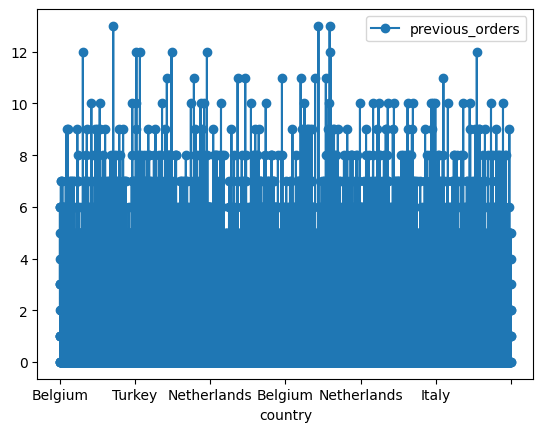

In [26]:
df.plot(x='country', y='previous_orders', kind='line', marker='o')

Text(0, 0.5, 'previous_orders')

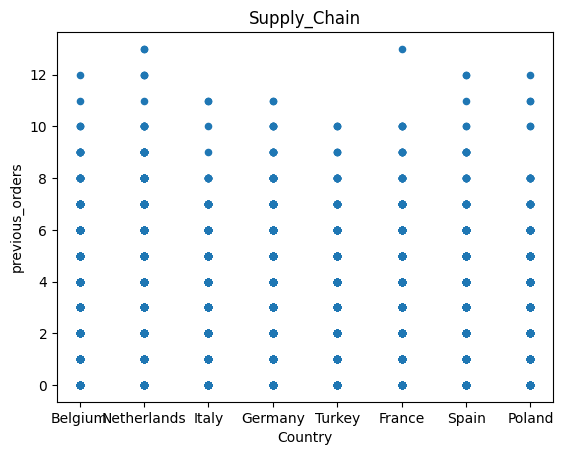

In [27]:
from matplotlib.colors import Colormap
df.plot(x='country', y='previous_orders', kind='scatter', marker='o')
plt.title('Supply_Chain')
plt.xlabel('Country')
plt.ylabel('previous_orders')